# 03 — Visualizations

1. Maps of amenity complexity (ECI): whole metro and zoomed in, for New York, Detroit, Boston and Los Angeles
2. Bar plots: ranking of the cities and of the neighborhoods
3. Scatter plots: ECI vs. income, population and education

Uses the final (filtered) results saved at the end of notebook 06:
`eci_per_city_filtered.parquet` and `eci_pooled_filtered.parquet`.

In [14]:
# ── imports ───────────────────────────────────────────────────────────────────
import json
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ── font sizes ────────────────────────────────────────────────────────────────
FS = 10
FS2 = FS - 2
FS4 = FS - 4

# ── paths ─────────────────────────────────────────────────────────────────────
RAW = "C:/Users/pc/Downloads/data/raw/"
PROCESSED = "C:/Users/pc/Downloads/data/processed/"
FIGS = "C:/Users/pc/Downloads/data/figures/"
os.makedirs(FIGS, exist_ok=True)

# ── city used in the single-city plots ────────────────────────────────────────
CBSA = "14460"      # Boston

## 0. Load data

In [15]:
# LOAD
# ── census tracts: name + metro of each tract ────────────────────────────────
with open(RAW + "censustract_geoms_top50.geojson") as f:
    features = [json.loads(line) for line in f]
tracts = gpd.GeoDataFrame.from_features(features, crs="EPSG:4326")[["full_geoid", "display_name", "geometry"]]

metros = gpd.read_file(RAW + "metro_areas/metro_areas.shp").to_crs("EPSG:4326")[["cbsacode", "geometry"]]
metros["cbsacode"] = metros["cbsacode"].astype(str)

centroids = tracts.copy()
centroids["geometry"] = tracts.to_crs("EPSG:5070").centroid.to_crs("EPSG:4326")
centroids = gpd.sjoin(centroids, metros, how="left", predicate="within")
tracts = tracts.merge(centroids[["full_geoid", "cbsacode"]].drop_duplicates("full_geoid"), on="full_geoid")

In [27]:
# ── ECI (single-city and pooled, filtered categories) ────────────────────────
eci_city = pd.read_parquet(PROCESSED + "eci_per_city_filtered.parquet")
eci_pooled = pd.read_parquet(PROCESSED + "eci_pooled_filtered.parquet")
eci_city["cbsacode"] = eci_city["cbsacode"].astype(str)
eci_pooled["cbsacode"] = eci_pooled["cbsacode"].astype(str)

# ── income, population, education (ACS 2020) ─────────────────────────────────
acs = pd.read_csv(RAW + "acs_data_census_tracts_2012_2020.csv.gz",
                  usecols=["tract_id", "population2020", "income2020",
                           "education_bachelor2020", "education_total2020"])
acs = acs.rename(columns={"tract_id": "census_tract_ID", "population2020": "population",
                          "income2020": "income"})
acs["bachelor_share"] = acs["education_bachelor2020"] / acs["education_total2020"]

print(f"Tracts with ECI: {len(eci_city)}, metros: {eci_city['cbsacode'].nunique()}")

Tracts with ECI: 38556, metros: 50


In [17]:
# ── city names (for the plots) ───────────────────────────────────────────────
NAMES = {
    "35620": "New York", "31080": "Los Angeles", "16980": "Chicago", "19100": "Dallas-Fort Worth",
    "26420": "Houston", "47900": "Washington DC", "37980": "Philadelphia", "33100": "Miami",
    "12060": "Atlanta", "14460": "Boston", "38060": "Phoenix", "41860": "San Francisco",
    "40140": "Riverside", "19820": "Detroit", "42660": "Seattle", "33460": "Minneapolis",
    "41740": "San Diego", "45300": "Tampa", "19740": "Denver", "12580": "Baltimore",
    "41180": "St. Louis", "36740": "Orlando", "16740": "Charlotte", "41700": "San Antonio",
    "38900": "Portland", "40900": "Sacramento", "38300": "Pittsburgh", "12420": "Austin",
    "29820": "Las Vegas", "17140": "Cincinnati", "28140": "Kansas City", "18140": "Columbus",
    "26900": "Indianapolis", "17460": "Cleveland", "41940": "San Jose", "34980": "Nashville",
    "47260": "Virginia Beach", "39300": "Providence", "33340": "Milwaukee", "27260": "Jacksonville",
    "36420": "Oklahoma City", "39580": "Raleigh", "32820": "Memphis", "40060": "Richmond",
    "31140": "Louisville", "35380": "New Orleans", "41620": "Salt Lake City", "25540": "Hartford",
    "15380": "Buffalo", "13820": "Birmingham",
}

## 1. Maps

In [18]:
# ── example cities: name, main center (lat, lon), zoom radius in km ──────────
EXAMPLES = {
    "35620": ("New York",    40.7580,  -73.9855, 15),     # Times Square
    "19820": ("Detroit",     42.3314,  -83.0458, 15),     # Campus Martius
    "14460": ("Boston",      42.3554,  -71.0605, 10),     # Downtown Crossing
    "31080": ("Los Angeles", 34.0489, -118.2517, 20),     # Pershing Square
}


# ── map of the ECI of one city (radius_km=None: the whole metro) ─────────────
def plot_eci_map(cbsa, ax, radius_km=None):
    name, clat, clon, _ = EXAMPLES[cbsa]
    t = tracts[tracts["cbsacode"] == cbsa].merge(
        eci_city[eci_city["cbsacode"] == cbsa][["census_tract_ID", "eci"]],
        left_on="full_geoid", right_on="census_tract_ID", how="left")
    center_pt = gpd.GeoSeries(gpd.points_from_xy([clon], [clat]), crs="EPSG:4326")

    if radius_km is not None:                                   # distances in meters (equal-area projection)
        dist = t.to_crs("EPSG:5070").centroid.distance(center_pt.to_crs("EPSG:5070").iloc[0])
        t = t[dist <= radius_km * 1000]

    t = t.to_crs("EPSG:3857")                                   # north is up on the map
    center = center_pt.to_crs("EPSG:3857").iloc[0]

    # color scale from the 2nd to the 98th percentile
    vmin, vmax = t["eci"].quantile([0.02, 0.98])
    t.plot(column="eci", cmap="viridis", vmin=vmin, vmax=vmax, ax=ax,
           edgecolor="white", linewidth=0.1, missing_kwds={"color": "lightgrey"})
    ax.scatter(center.x, center.y, marker="*", s=150, color="red", edgecolor="black", zorder=5)
    ax.set_axis_off()
    ax.set_title(name if radius_km is None else f"{name} ({radius_km} km around the center)", fontsize=FS)

    sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(vmin, vmax))
    ax.figure.colorbar(sm, ax=ax, shrink=0.6, label="ECI")

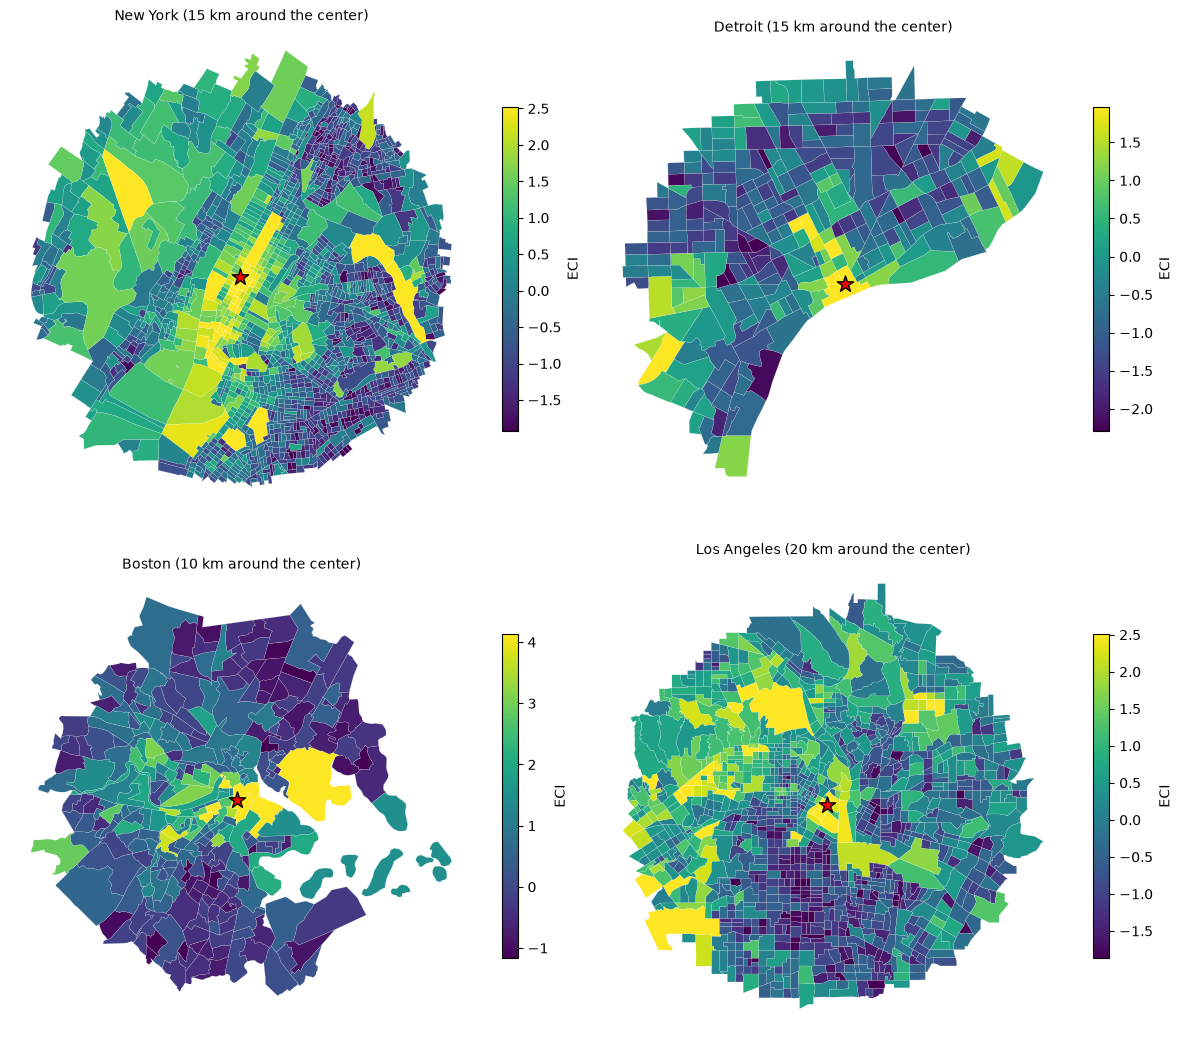

In [19]:
# ── zoomed-in maps of the four example cities ────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for ax, cbsa in zip(axes.flat, EXAMPLES):
    plot_eci_map(cbsa, ax, radius_km=EXAMPLES[cbsa][3])
fig.tight_layout()
fig.savefig(FIGS + "maps_eci_zoomed.png", dpi=200, bbox_inches="tight")

The maps show that higher amenity complexity tends to concentrate around urban centers, particularly in Boston and New York. Los Angeles exhibits a more dispersed pattern, with multiple pockets of high complexity beyond its main city center.

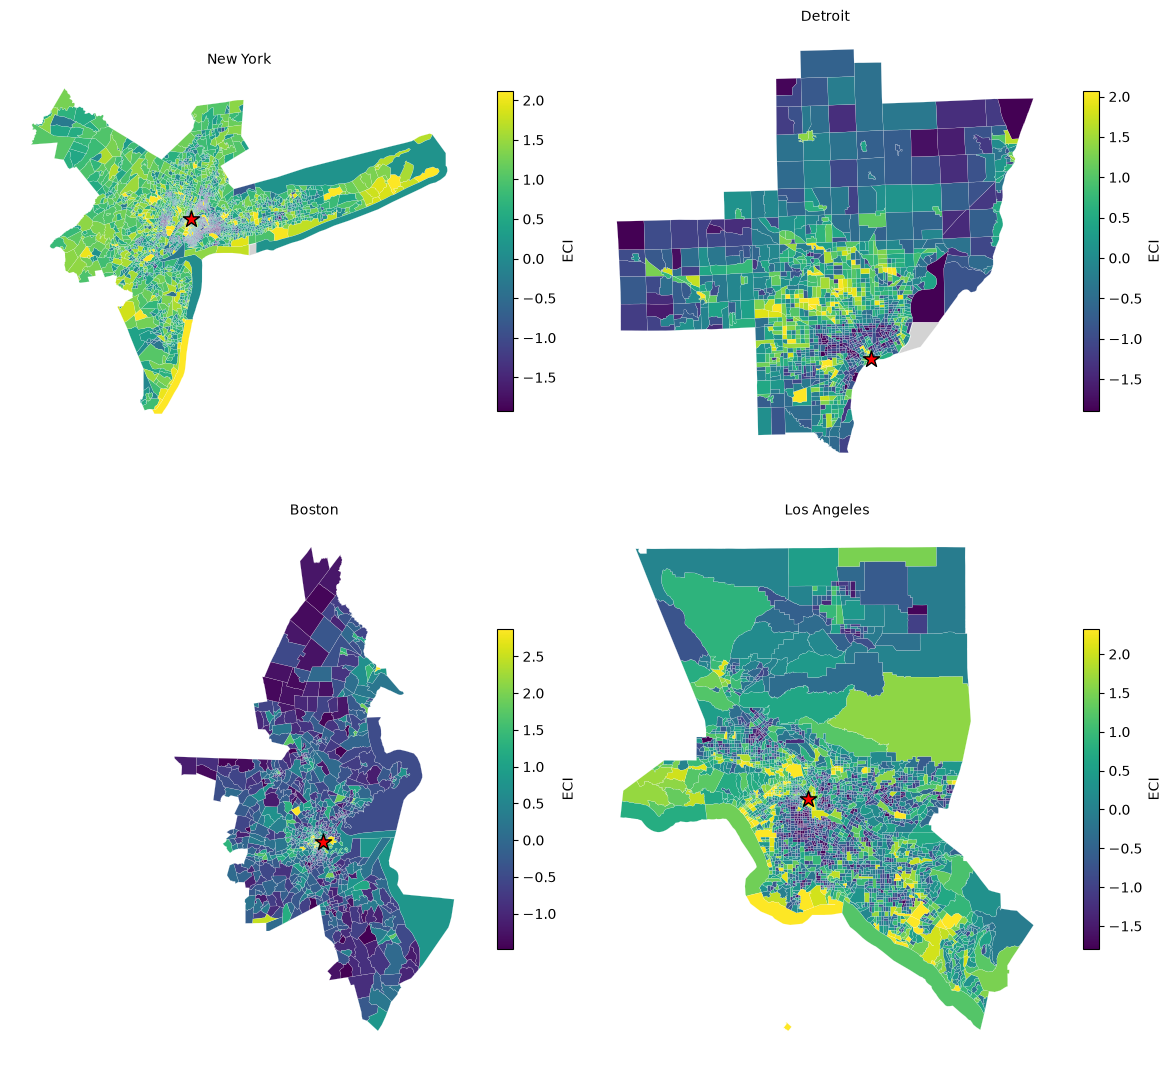

In [20]:
# ── the same cities, whole metropolitan area ─────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for ax, cbsa in zip(axes.flat, EXAMPLES):
    plot_eci_map(cbsa, ax, radius_km=None)
fig.tight_layout()
fig.savefig(FIGS + "maps_eci_metro.png", dpi=200, bbox_inches="tight")

## 2. Bar plots

**Cities:** the single-city ECI is standardized inside each metro (mean 0), so it cannot rank cities.
The pooled ECI puts all tracts on the same scale, so we rank the cities by the average pooled ECI of their tracts.

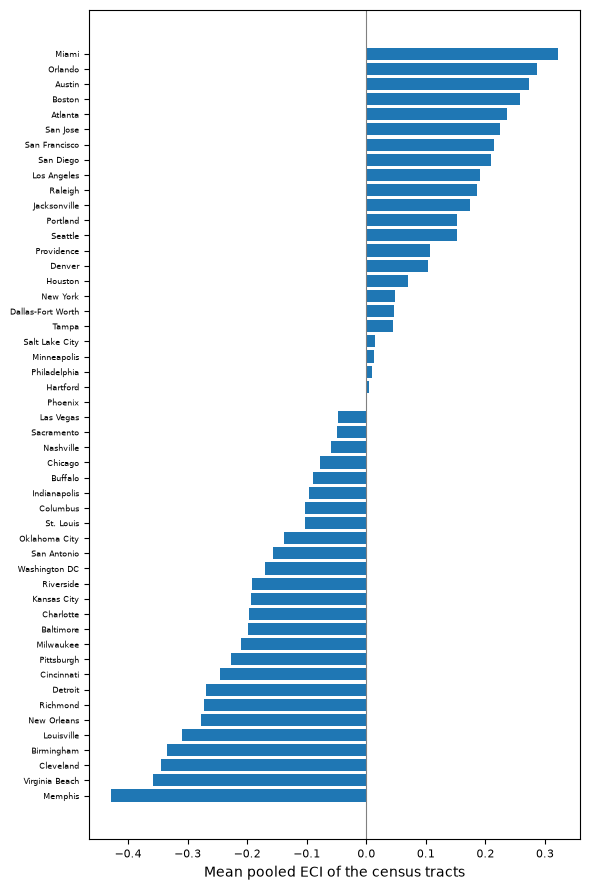

In [21]:
# ── ranking of the cities: mean pooled ECI of the tracts ────────────────────
city_rank = eci_pooled.groupby("cbsacode")["eci"].mean().sort_values()
city_rank.index = [NAMES.get(c, c) for c in city_rank.index]

fig, ax = plt.subplots(figsize=(6, 9))
ax.barh(city_rank.index, city_rank.values, color="tab:blue")
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Mean pooled ECI of the census tracts", fontsize=FS)
ax.tick_params(axis="y", labelsize=FS4)
ax.tick_params(axis="x", labelsize=FS2)
fig.tight_layout()
fig.savefig(FIGS + "bar_city_ranking.png", dpi=200, bbox_inches="tight")

Average pooled ECI reveals substantial variation in neighborhood amenity complexity across metropolitan areas, with Miami, Orlando and Austin ranking highest and Memphis, Virginia Beach and Cleveland ranking lowest.

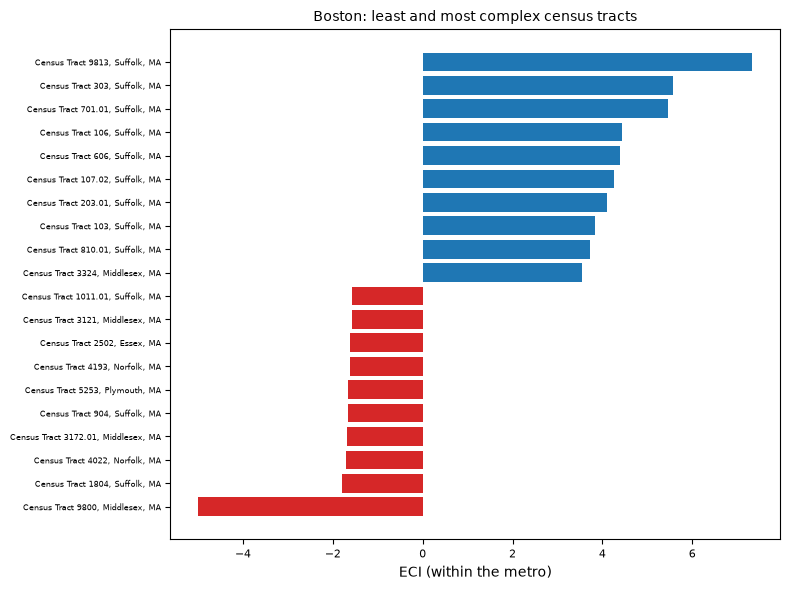

In [22]:
# ── ranking of the neighborhoods: 10 most and 10 least complex tracts ────────
e = eci_city[eci_city["cbsacode"] == CBSA].merge(
    tracts[["full_geoid", "display_name"]], left_on="census_tract_ID", right_on="full_geoid")
e = e.sort_values("eci")
extremes = pd.concat([e.head(10), e.tail(10)])

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["tab:red"] * 10 + ["tab:blue"] * 10
ax.barh(extremes["display_name"], extremes["eci"], color=colors)
ax.set_xlabel("ECI (within the metro)", fontsize=FS)
ax.set_title(f"{NAMES.get(CBSA, CBSA)}: least and most complex census tracts", fontsize=FS)
ax.tick_params(axis="y", labelsize=FS4)
ax.tick_params(axis="x", labelsize=FS2)
fig.tight_layout()
fig.savefig(FIGS + f"bar_tracts_{CBSA}.png", dpi=200, bbox_inches="tight")

Most of Boston's highest-complexity census tracts are concentrated in Suffolk County, while the lowest-complexity tracts are more geographically dispersed. This highlights substantial differences in amenity complexity within the same metropolitan area.

## 3. Scatter plots: ECI vs. income, population and education

In [23]:
# ── data: ECI + socioeconomic variables ──────────────────────────────────────
df = eci_city.merge(acs, on="census_tract_ID", how="left")
df = df[(df["income"] > 0) & (df["population"] > 0)].copy()
df["log_income"] = np.log(df["income"])
df["log_population"] = np.log(df["population"])

# income relative to the metro average (so that rich and poor metros can be pooled)
df["log_income_rel"] = df["log_income"] - df.groupby("cbsacode")["log_income"].transform("mean")
print(f"Tracts with ECI, income and population: {len(df)}")

Tracts with ECI, income and population: 32602


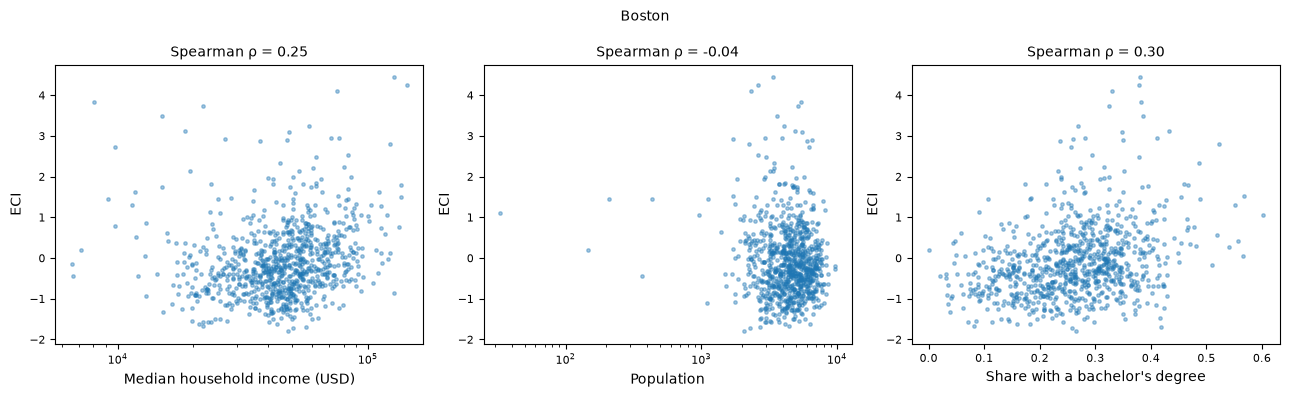

In [24]:
# ── one city: ECI vs. income, population and share with a bachelor's degree ──
d = df[df["cbsacode"] == CBSA]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, var, label, log_x in zip(
        axes,
        ["income", "population", "bachelor_share"],
        ["Median household income (USD)", "Population", "Share with a bachelor's degree"],
        [True, True, False]):
    x = d.dropna(subset=[var])
    rho = spearmanr(x["eci"], x[var])[0]
    ax.scatter(x[var], x["eci"], s=6, alpha=0.4, color="tab:blue")
    if log_x:
        ax.set_xscale("log")
    ax.set_xlabel(label, fontsize=FS)
    ax.set_ylabel("ECI", fontsize=FS)
    ax.set_title(f"Spearman ρ = {rho:.2f}", fontsize=FS)
    ax.tick_params(labelsize=FS2)
fig.suptitle(NAMES.get(CBSA, CBSA), fontsize=FS)
fig.tight_layout()
fig.savefig(FIGS + f"scatter_{CBSA}.png", dpi=200, bbox_inches="tight")

1. More complex neighborhoods tend to have wealthier residents.
2. More populated neighborhoods are not necessarily more complex.
3. More complex neighborhoods tend to have a more educated population.

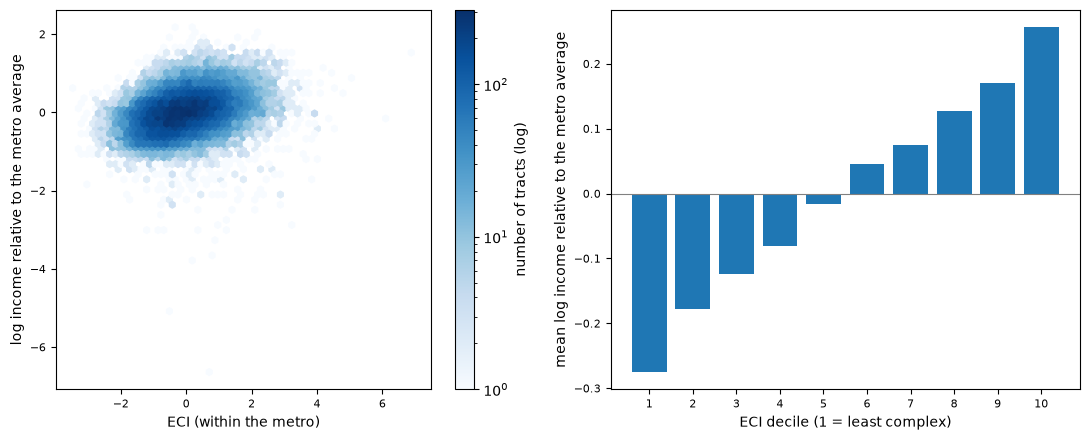

In [25]:
# ── all cities: ECI vs. income relative to the metro average ─────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

hb = axes[0].hexbin(df["eci"], df["log_income_rel"], gridsize=60, bins="log", cmap="Blues", mincnt=1)
axes[0].set_xlabel("ECI (within the metro)", fontsize=FS)
axes[0].set_ylabel("log income relative to the metro average", fontsize=FS)
fig.colorbar(hb, ax=axes[0], label="number of tracts (log)")

# average income by ECI decile
df["eci_decile"] = pd.qcut(df["eci"], 10, labels=False) + 1
by_decile = df.groupby("eci_decile")["log_income_rel"].mean()
axes[1].bar(by_decile.index, by_decile.values, color="tab:blue")
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set_xlabel("ECI decile (1 = least complex)", fontsize=FS)
axes[1].set_ylabel("mean log income relative to the metro average", fontsize=FS)
axes[1].set_xticks(range(1, 11))
for ax in axes:
    ax.tick_params(labelsize=FS2)
fig.tight_layout()
fig.savefig(FIGS + "scatter_all_cities.png", dpi=200, bbox_inches="tight")

1. Across the metropolitan areas studied, neighborhoods with higher ECI tend to have higher income relative to their own metro average. However, the dispersion of observations indicates that amenity complexity alone does not explain income differences.
2. Average relative income increases consistently across all ten ECI deciles. The least complex neighborhoods tend to have below-average income, while the most complex neighborhoods tend to have above-average income relative to their metropolitan area.